# DS605 Lab Assignment 8


In [1]:
import os
import time
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.base import clone

RANDOM_STATE = 42
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = ROOT_DIR / "results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (8, 5)


## Load the Banknote Authentication Dataset

In [2]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
DATA_PATH = ROOT_DIR / "banknote_authentication.csv"
COLUMN_NAMES = ["variance", "skewness", "curtosis", "entropy", "class"]

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    try:
        df = pd.read_csv(DATA_URL, header=None, names=COLUMN_NAMES)
        df.to_csv(DATA_PATH, index=False)
    except Exception as exc:
        raise RuntimeError(
            "Could not download the UCI dataset. Download data_banknote_authentication.txt "
            "from the UCI Banknote Authentication dataset and save it as "
            "'banknote_authentication.csv' in the repository root."
        ) from exc

if list(df.columns) != COLUMN_NAMES:
    if df.shape[1] == 5:
        df.columns = COLUMN_NAMES
    else:
        raise ValueError("Expected four feature columns and one class column.")

df = df.dropna().copy()
df["class"] = df["class"].astype(int)
X = df[COLUMN_NAMES[:-1]].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

print("Dataset shape:", df.shape)
print("Class counts:\n", df["class"].value_counts().sort_index())
display(df.head())

Dataset shape: (1372, 5)
Class counts:
 class
0    762
1    610
Name: count, dtype: int64


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


## Part A — Decision Tree from Scratch

In [3]:

def gini_impurity(labels):
    labels = np.asarray(labels)
    if len(labels) == 0:
        return 0.0
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()
    return float(1.0 - np.sum(probabilities ** 2))


def entropy(labels):
    labels = np.asarray(labels)
    if len(labels) == 0:
        return 0.0
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()
    return float(-np.sum(probabilities * np.log2(probabilities + 1e-15)))


class ManualDecisionTree:
    def __init__(self, criterion="gini", max_depth=5, min_samples_split=2,
                 min_samples_leaf=1, max_thresholds=100):
        if criterion not in ("gini", "entropy"):
            raise ValueError("criterion must be 'gini' or 'entropy'")
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_thresholds = max_thresholds
        self.root = None
        self.n_features_in_ = None

    def _impurity(self, labels):
        return gini_impurity(labels) if self.criterion == "gini" else entropy(labels)

    def _best_split(self, X, y):
        n_samples, n_features = X.shape
        parent_impurity = self._impurity(y)
        best_gain, best_feature, best_threshold = 0.0, None, None

        for feature in range(n_features):
            values = np.unique(X[:, feature])
            if len(values) < 2:
                continue
            thresholds = (values[:-1] + values[1:]) / 2.0
            if len(thresholds) > self.max_thresholds:
                indices = np.linspace(0, len(thresholds)-1, self.max_thresholds).astype(int)
                thresholds = thresholds[indices]

            for threshold in thresholds:
                left = X[:, feature] <= threshold
                n_left, n_right = int(left.sum()), int((~left).sum())
                if min(n_left, n_right) < self.min_samples_leaf:
                    continue
                child_impurity = (
                    n_left / n_samples * self._impurity(y[left]) +
                    n_right / n_samples * self._impurity(y[~left])
                )
                gain = parent_impurity - child_impurity
                if gain > best_gain:
                    best_gain, best_feature, best_threshold = gain, feature, float(threshold)

        if best_feature is None:
            return None
        return best_feature, best_threshold, best_gain

    def _build(self, X, y, depth):
        values, counts = np.unique(y, return_counts=True)
        prediction = int(values[np.argmax(counts)])
        node = {"prediction": prediction, "samples": len(y), "class_counts": dict(zip(values.tolist(), counts.tolist())),
                "depth": depth, "feature": None, "threshold": None, "left": None, "right": None}
        if (len(values) == 1 or depth >= self.max_depth or len(y) < self.min_samples_split):
            return node
        split = self._best_split(X, y)
        if split is None:
            return node
        feature, threshold, gain = split
        left_mask = X[:, feature] <= threshold
        if left_mask.sum() == 0 or (~left_mask).sum() == 0:
            return node
        node.update({"feature": feature, "threshold": threshold, "gain": gain})
        node["left"] = self._build(X[left_mask], y[left_mask], depth + 1)
        node["right"] = self._build(X[~left_mask], y[~left_mask], depth + 1)
        return node

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, int)
        self.n_features_in_ = X.shape[1]
        self.root = self._build(X, y, 0)
        return self

    def _predict_one(self, row, node):
        while node["feature"] is not None:
            if row[node["feature"]] <= node["threshold"]:
                node = node["left"]
            else:
                node = node["right"]
        return node["prediction"]

    def predict(self, X):
        X = np.asarray(X, float)
        return np.array([self._predict_one(row, self.root) for row in X], dtype=int)

    def rules(self, feature_names):
        lines = []
        def walk(node, conditions, branch="ROOT"):
            if node["feature"] is None:
                lines.append(f"{'  ' * node['depth']}{branch}: IF {' AND '.join(conditions) if conditions else 'TRUE'} THEN class={node['prediction']} (n={node['samples']})")
                return
            name = feature_names[node["feature"]]
            walk(node["left"], conditions + [f"{name} <= {node['threshold']:.5g}"], "LEFT")
            walk(node["right"], conditions + [f"{name} > {node['threshold']:.5g}"], "RIGHT")
        walk(self.root, [])
        return "\n".join(lines)


## Part A — Two-Feature Decision Boundaries

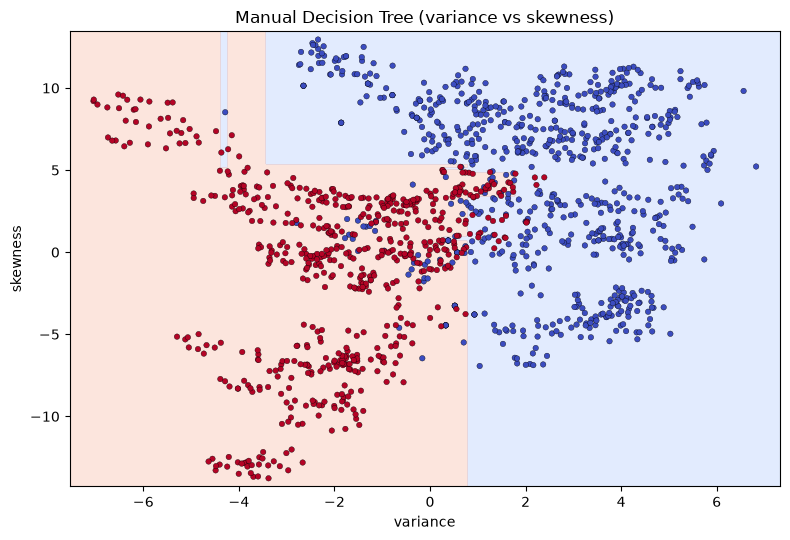

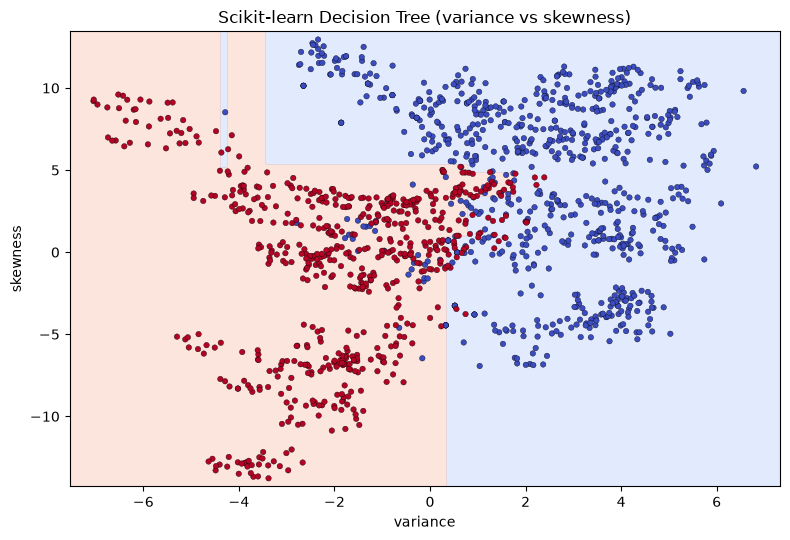

Manual tree rules:
          LEFT: IF variance <= 0.7651 AND skewness <= 5.1919 AND variance <= 0.30942 AND variance <= -0.45857 AND skewness <= 0.054827 THEN class=1 (n=193)
          RIGHT: IF variance <= 0.7651 AND skewness <= 5.1919 AND variance <= 0.30942 AND variance <= -0.45857 AND skewness > 0.054827 THEN class=1 (n=135)
          LEFT: IF variance <= 0.7651 AND skewness <= 5.1919 AND variance <= 0.30942 AND variance > -0.45857 AND skewness <= -0.1759 THEN class=1 (n=23)
          RIGHT: IF variance <= 0.7651 AND skewness <= 5.1919 AND variance <= 0.30942 AND variance > -0.45857 AND skewness > -0.1759 THEN class=1 (n=38)
          LEFT: IF variance <= 0.7651 AND skewness <= 5.1919 AND variance > 0.30942 AND skewness <= 0.98186 AND skewness <= 0.68182 THEN class=1 (n=23)
          RIGHT: IF variance <= 0.7651 AND skewness <= 5.1919 AND variance > 0.30942 AND skewness <= 0.98186 AND skewness > 0.68182 THEN class=0 (n=5)
          LEFT: IF variance <= 0.7651 AND skewness <= 5.1919

In [4]:

FEATURE_INDICES = [0, 1]
FEATURE_NAMES_2D = [COLUMN_NAMES[i] for i in FEATURE_INDICES]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
X2 = X[:, FEATURE_INDICES]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

def plot_boundary(model, X_plot, y_plot, title, filename, feature_names=FEATURE_NAMES_2D):
    x_min, x_max = X_plot[:, 0].min() - 0.5, X_plot[:, 0].max() + 0.5
    y_min, y_max = X_plot[:, 1].min() - 0.5, X_plot[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)
    plt.figure(figsize=(8, 5.5))
    plt.contourf(xx, yy, zz, alpha=0.25, levels=np.arange(-0.5, len(np.unique(y_plot))+0.5, 1), cmap="coolwarm")
    plt.scatter(X_plot[:, 0], X_plot[:, 1], c=y_plot, s=16, edgecolors="k", linewidths=0.25, cmap="coolwarm")
    plt.xlabel(feature_names[0]); plt.ylabel(feature_names[1]); plt.title(title)
    plt.tight_layout(); plt.savefig(OUTPUT_DIR / filename, dpi=160); plt.show()

manual_tree_2d = ManualDecisionTree(criterion="gini", max_depth=5).fit(X2_train, y2_train)
sk_tree_2d = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=RANDOM_STATE).fit(X2_train, y2_train)
plot_boundary(manual_tree_2d, X2, y, "Manual Decision Tree (variance vs skewness)", "manual_tree_boundary.png")
plot_boundary(sk_tree_2d, X2, y, "Scikit-learn Decision Tree (variance vs skewness)", "sklearn_tree_boundary.png")

print("Manual tree rules:")
print(manual_tree_2d.rules(FEATURE_NAMES_2D))
print("\nManual accuracy:", accuracy_score(y2_test, manual_tree_2d.predict(X2_test)))
print("Scikit-learn accuracy:", accuracy_score(y2_test, sk_tree_2d.predict(X2_test)))
print("Prediction agreement:", np.mean(manual_tree_2d.predict(X2_test) == sk_tree_2d.predict(X2_test)))


## Part A — Manual Tree Visualization

In [8]:
def plot_manual_tree(root, feature_names, filename="manual_tree_structure.png"):

    nodes = []

    def collect(node, depth=0):
        idx = len(nodes)

        nodes.append({
            "node": node,
            "depth": depth,
            "left": None,
            "right": None
        })

        if node["feature"] is not None:
            nodes[idx]["left"] = collect(node["left"], depth + 1)
            nodes[idx]["right"] = collect(node["right"], depth + 1)

        return idx

    collect(root)

    positions = {}
    leaf_counter = [0]

    def layout(idx):
        item = nodes[idx]

        if item["left"] is None:
            x = leaf_counter[0]
            leaf_counter[0] += 1
        else:
            left_x, _ = layout(item["left"])
            right_x, _ = layout(item["right"])
            x = (left_x + right_x) / 2

        positions[idx] = (x, -item["depth"])

        return positions[idx]

    layout(0)

    max_depth = max(item["depth"] for item in nodes)
    total_leaves = leaf_counter[0]

    fig, ax = plt.subplots(
        figsize=(
            max(12, total_leaves * 1.5),
            max(5, (max_depth + 1) * 1.5)
        )
    )

    # Draw connections first so the node boxes appear above them.
    for idx, item in enumerate(nodes):

        x, y_pos = positions[idx]

        for child in (item["left"], item["right"]):

            if child is not None:
                child_x, child_y = positions[child]

                ax.annotate(
                    "",
                    xy=(child_x, child_y + 0.15),
                    xytext=(x, y_pos - 0.15),
                    arrowprops=dict(
                        arrowstyle="->",
                        color="black",
                        linewidth=1
                    )
                )

    # Draw decision and leaf nodes.
    for idx, item in enumerate(nodes):

        node = item["node"]
        x, y_pos = positions[idx]

        if node["feature"] is None:

            label = (
                f"LEAF\n"
                f"Class: {node['prediction']}\n"
                f"Samples: {node['samples']}"
            )

        else:

            label = (
                f"{feature_names[node['feature']]} <= "
                f"{node['threshold']:.3f}\n"
                f"Samples: {node['samples']}"
            )

        ax.text(
            x,
            y_pos,
            label,
            ha="center",
            va="center",
            fontsize=8,
            bbox=dict(
                boxstyle="round,pad=0.5",
                facecolor="lightyellow" if node["feature"] is not None
                else "lightgreen",
                edgecolor="black",
                linewidth=1
            ),
            zorder=3
        )

    ax.set_title("Manual Decision Tree Structure", fontsize=14)
    ax.set_axis_off()

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()


plot_manual_tree(manual_tree_2d.root, FEATURE_NAMES_2D)


## Part A — Criterion and Maximum-Depth Experiments

In [14]:
import numpy as np
import pandas as pd
import time

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score


def gini_impurity(labels):
    labels = np.asarray(labels)

    if len(labels) == 0:
        return 0.0

    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / len(labels)

    return 1.0 - np.sum(probabilities ** 2)


def entropy(labels):
    labels = np.asarray(labels)

    if len(labels) == 0:
        return 0.0

    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / len(labels)

    return -np.sum(
        probabilities * np.log2(probabilities + 1e-15)
    )


class ManualDecisionTree:

    def __init__(
        self,
        criterion="gini",
        max_depth=5,
        min_samples_split=2,
        min_samples_leaf=1,
        max_thresholds=100
    ):

        if criterion not in ("gini", "entropy"):
            raise ValueError(
                "criterion must be 'gini' or 'entropy'"
            )

        if max_depth is not None and max_depth < 0:
            raise ValueError(
                "max_depth must be non-negative or None"
            )

        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_thresholds = max_thresholds

        self.root = None
        self.n_features_in_ = None

    def _impurity(self, labels):

        if self.criterion == "gini":
            return gini_impurity(labels)

        return entropy(labels)

    def _best_split(self, X, y):

        n_samples, n_features = X.shape

        parent_impurity = self._impurity(y)

        best_gain = 0.0
        best_feature = None
        best_threshold = None

        for feature in range(n_features):

            values = np.unique(X[:, feature])

            if len(values) < 2:
                continue

            thresholds = (
                values[:-1] + values[1:]
            ) / 2.0

            if len(thresholds) > self.max_thresholds:

                indices = np.linspace(
                    0,
                    len(thresholds) - 1,
                    self.max_thresholds
                ).astype(int)

                thresholds = thresholds[indices]

            for threshold in thresholds:

                left_mask = X[:, feature] <= threshold

                n_left = np.sum(left_mask)
                n_right = n_samples - n_left

                if (
                    n_left < self.min_samples_leaf
                    or n_right < self.min_samples_leaf
                ):
                    continue

                y_left = y[left_mask]
                y_right = y[~left_mask]

                weighted_impurity = (
                    (n_left / n_samples)
                    * self._impurity(y_left)
                    +
                    (n_right / n_samples)
                    * self._impurity(y_right)
                )

                gain = parent_impurity - weighted_impurity

                if gain > best_gain:

                    best_gain = gain
                    best_feature = feature
                    best_threshold = float(threshold)

        if best_feature is None:
            return None

        return best_feature, best_threshold, best_gain

    def _build(self, X, y, depth):

        values, counts = np.unique(
            y,
            return_counts=True
        )

        prediction = int(values[np.argmax(counts)])

        node = {
            "prediction": prediction,
            "samples": len(y),
            "class_counts": dict(
                zip(values.tolist(), counts.tolist())
            ),
            "depth": depth,
            "feature": None,
            "threshold": None,
            "left": None,
            "right": None
        }

        # Stop if the node contains only one class.
        if len(values) == 1:
            return node

        # IMPORTANT: None means no maximum-depth restriction.
        if (
            self.max_depth is not None
            and depth >= self.max_depth
        ):
            return node

        if len(y) < self.min_samples_split:
            return node

        split = self._best_split(X, y)

        if split is None:
            return node

        feature, threshold, gain = split

        left_mask = X[:, feature] <= threshold

        if (
            np.sum(left_mask) == 0
            or np.sum(~left_mask) == 0
        ):
            return node

        node["feature"] = feature
        node["threshold"] = threshold
        node["gain"] = gain

        node["left"] = self._build(
            X[left_mask],
            y[left_mask],
            depth + 1
        )

        node["right"] = self._build(
            X[~left_mask],
            y[~left_mask],
            depth + 1
        )

        return node

    def fit(self, X, y):

        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)

        if X.ndim != 2:
            raise ValueError("X must be a 2D array.")

        if len(X) != len(y):
            raise ValueError(
                "X and y must contain the same number of samples."
            )

        if len(y) == 0:
            raise ValueError("Training data cannot be empty.")

        if not np.all(np.isfinite(X)):
            raise ValueError(
                "X contains NaN or infinite values."
            )

        self.n_features_in_ = X.shape[1]

        self.root = self._build(X, y, depth=0)

        return self

    def _predict_one(self, row, node):

        while node["feature"] is not None:

            if row[node["feature"]] <= node["threshold"]:
                node = node["left"]
            else:
                node = node["right"]

        return node["prediction"]

    def predict(self, X):

        if self.root is None:
            raise ValueError(
                "Fit the decision tree before predicting."
            )

        X = np.asarray(X, dtype=float)

        if X.ndim != 2:
            raise ValueError("X must be a 2D array.")

        if X.shape[1] != self.n_features_in_:
            raise ValueError(
                "Prediction data has the wrong number of features."
            )

        return np.array([
            self._predict_one(row, self.root)
            for row in X
        ], dtype=int)



tree_experiments = []

for criterion in ("gini", "entropy"):

    for depth in (2, 3, 5, 8, None):

        print(
            f"Running: criterion={criterion}, "
            f"max_depth={depth}"
        )

        # Manual Decision Tree
        manual = ManualDecisionTree(
            criterion=criterion,
            max_depth=depth
        )

        start = time.perf_counter()

        manual.fit(X2_train, y2_train)

        manual_train_time = time.perf_counter() - start

        start = time.perf_counter()

        manual_pred = manual.predict(X2_test)

        manual_pred_time = time.perf_counter() - start

        # Scikit-learn Decision Tree
        sklearn_model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=RANDOM_STATE
        )

        start = time.perf_counter()

        sklearn_model.fit(X2_train, y2_train)

        sklearn_train_time = time.perf_counter() - start

        start = time.perf_counter()

        sklearn_pred = sklearn_model.predict(X2_test)

        sklearn_pred_time = time.perf_counter() - start

        # Save results
        tree_experiments.append({

            "criterion": criterion,

            "max_depth": (
                depth if depth is not None
                else "Unlimited"
            ),

            "manual_accuracy": accuracy_score(
                y2_test,
                manual_pred
            ),

            "sklearn_accuracy": accuracy_score(
                y2_test,
                sklearn_pred
            ),

            "manual_training_seconds": manual_train_time,

            "manual_prediction_seconds": manual_pred_time,

            "sklearn_training_seconds": sklearn_train_time,

            "sklearn_prediction_seconds": sklearn_pred_time,

            "prediction_agreement": np.mean(
                manual_pred == sklearn_pred
            )
        })


tree_experiment_df = pd.DataFrame(tree_experiments)

display(tree_experiment_df)

tree_experiment_df.to_csv(
    OUTPUT_DIR / "tree_experiments.csv",
    index=False
)

print("Experiments completed successfully!")


Running: criterion=gini, max_depth=2
Running: criterion=gini, max_depth=3
Running: criterion=gini, max_depth=5
Running: criterion=gini, max_depth=8
Running: criterion=gini, max_depth=None
Running: criterion=entropy, max_depth=2
Running: criterion=entropy, max_depth=3
Running: criterion=entropy, max_depth=5
Running: criterion=entropy, max_depth=8
Running: criterion=entropy, max_depth=None


,criterion,max_depth,manual_accuracy,sklearn_accuracy,manual_training_seconds,manual_prediction_seconds,sklearn_training_seconds,sklearn_prediction_seconds,prediction_agreement
0,gini,2,0.865889,0.865889,0.017567,0.000130,0.001076,0.000117,1.000000
1,gini,3,0.906706,0.906706,0.033800,0.000151,0.000965,0.000099,1.000000
2,gini,5,0.909621,0.930029,0.065812,0.000197,0.001275,0.000127,0.967930
3,gini,8,0.924198,0.924198,0.094697,0.000267,0.001505,0.000147,1.000000
4,gini,Unlimited,0.927114,0.918367,0.108143,0.000232,0.001113,0.000099,0.991254
5,entropy,2,0.865889,0.865889,0.026277,0.000116,0.001220,0.000108,1.000000
6,entropy,3,0.897959,0.897959,0.031091,0.000168,0.001069,0.000095,1.000000
7,entropy,5,0.924198,0.932945,0.070481,0.000173,0.001291,0.000109,0.991254
8,entropy,8,0.927114,0.930029,0.089981,0.000193,0.001224,0.000140,0.985423
9,entropy,Unlimited,0.909621,0.909621,0.091636,0.000212,0.001215,0.000100,0.994169


Experiments completed successfully!


## Part B — Linear SVM from Scratch

In [11]:

class ManualLinearSVM:
    def __init__(self, C=1.0, learning_rate=0.001, n_iter=5000, random_state=42):
        self.C = C
        self.learning_rate = learning_rate
        self.n_iter = n_iter
        self.random_state = random_state
        self.w = None
        self.b = 0.0
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, float)
        y = np.where(np.asarray(y) == np.unique(y)[0], -1.0, 1.0)
        rng = np.random.default_rng(self.random_state)
        self.w = np.zeros(X.shape[1], dtype=float)
        self.b = 0.0
        n = len(y)
        for step in range(self.n_iter):
            margins = y * (X @ self.w + self.b)
            violating = margins < 1.0
            grad_w = self.w - self.C * np.sum((y[violating, None] * X[violating]), axis=0)
            grad_b = -self.C * np.sum(y[violating])
            # Averaging the hinge-loss term keeps the optimization scale stable across dataset sizes.
            grad_w = self.w - self.C * np.sum(y[violating, None] * X[violating], axis=0) / n
            grad_b = -self.C * np.sum(y[violating]) / n
            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b
            if step % max(1, self.n_iter // 100) == 0:
                hinge = np.maximum(0, 1 - y * (X @ self.w + self.b))
                self.loss_history.append(0.5 * np.dot(self.w, self.w) + self.C * np.mean(hinge))
        return self

    def decision_function(self, X):
        return np.asarray(X, float) @ self.w + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)


## Part B — Two-Feature SVM Boundaries and Margins

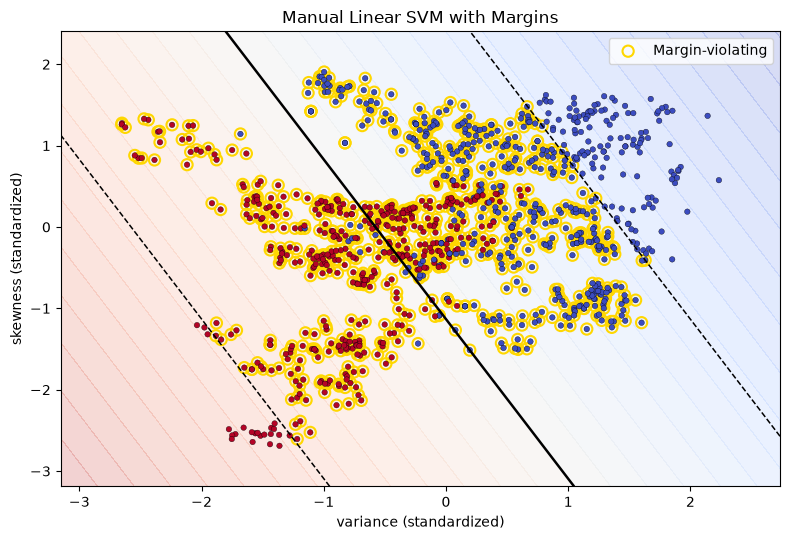

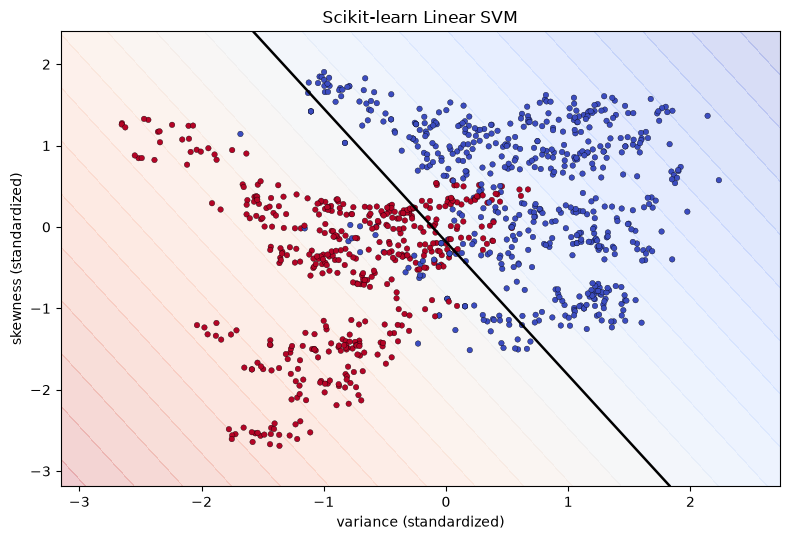

Manual SVM test accuracy: 0.8717201166180758
Scikit-learn SVM test accuracy: 0.8892128279883382


In [10]:

# Fit scaling only on the training subset; reuse it for test data and plotting.
scaler2 = StandardScaler().fit(X2_train)
X2_train_scaled = scaler2.transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)
y2_svm_train = np.where(y2_train == np.unique(y2_train)[0], -1, 1)
y2_svm_test = np.where(y2_test == np.unique(y2_test)[0], -1, 1)

manual_svm_2d = ManualLinearSVM(C=1.0, learning_rate=0.01, n_iter=8000).fit(X2_train_scaled, y2_train)
sk_svm_2d = SVC(kernel="linear", C=1.0).fit(X2_train_scaled, y2_train)

def plot_svm_boundary(model, X_scaled, y_labels, title, filename, show_margins=False):
    x_min, x_max = X_scaled[:, 0].min()-0.5, X_scaled[:, 0].max()+0.5
    y_min, y_max = X_scaled[:, 1].min()-0.5, X_scaled[:, 1].max()+0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    if hasattr(model, "decision_function"):
        scores = model.decision_function(grid)
    else:
        scores = model.decision_function(grid)
    plt.figure(figsize=(8, 5.5))
    plt.contourf(xx, yy, scores.reshape(xx.shape), levels=30, cmap="coolwarm", alpha=0.22)
    plt.contour(xx, yy, scores.reshape(xx.shape), levels=[0], colors="black", linewidths=1.8)
    if show_margins:
        plt.contour(xx, yy, scores.reshape(xx.shape), levels=[-1, 1], colors="black", linestyles="--", linewidths=1.1)
        signed_y = np.where(y_labels == np.unique(y_labels)[0], -1, 1)
        violations = signed_y * model.decision_function(X_scaled) < 1
        plt.scatter(X_scaled[violations, 0], X_scaled[violations, 1], s=65, facecolors="none", edgecolors="gold", linewidths=1.5, label="Margin-violating")
        plt.legend()
    plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_labels, s=16, edgecolors="k", linewidths=0.25, cmap="coolwarm")
    plt.xlabel("variance (standardized)"); plt.ylabel("skewness (standardized)")
    plt.title(title); plt.tight_layout(); plt.savefig(OUTPUT_DIR / filename, dpi=160); plt.show()

plot_svm_boundary(manual_svm_2d, X2_train_scaled, y2_train, "Manual Linear SVM with Margins", "manual_svm_margins.png", True)
plot_svm_boundary(sk_svm_2d, X2_train_scaled, y2_train, "Scikit-learn Linear SVM", "sklearn_svm_boundary.png")
print("Manual SVM test accuracy:", accuracy_score(y2_svm_test, manual_svm_2d.predict(X2_test_scaled)))
print("Scikit-learn SVM test accuracy:", accuracy_score(y2_test, sk_svm_2d.predict(X2_test_scaled)))


## Part B — Regularization, Learning Rate, and Iteration Experiments

In [11]:

svm_experiments = []
for C in (0.1, 1.0, 10.0):
    for lr in (0.001, 0.01):
        for iterations in (2000, 8000):
            model = ManualLinearSVM(C=C, learning_rate=lr, n_iter=iterations).fit(X2_train_scaled, y2_train)
            pred = model.predict(X2_test_scaled)
            svm_experiments.append({
                "C": C, "learning_rate": lr, "iterations": iterations,
                "manual_accuracy": accuracy_score(y2_svm_test, pred),
                "weight_norm": float(np.linalg.norm(model.w))
            })
display(pd.DataFrame(svm_experiments))
pd.DataFrame(svm_experiments).to_csv(OUTPUT_DIR / "svm_experiments.csv", index=False)


,C,learning_rate,iterations,manual_accuracy,weight_norm
0,0.1,0.001,2000,0.886297,0.072038
1,0.1,0.001,8000,0.790087,0.083272
2,0.1,0.010,2000,0.562682,0.083300
3,0.1,0.010,8000,0.556851,0.075815
4,1.0,0.001,2000,0.892128,0.565250
5,1.0,0.001,8000,0.874636,0.563069
6,1.0,0.010,2000,0.871720,0.561496
7,1.0,0.010,8000,0.871720,0.561438
8,10.0,0.001,2000,0.892128,1.209111
9,10.0,0.001,8000,0.892128,1.209095


## Part C — Kernel SVM and Nonlinear Boundaries

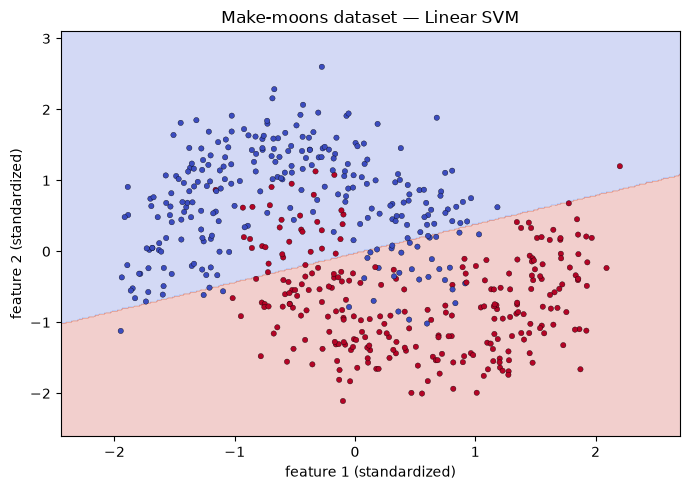

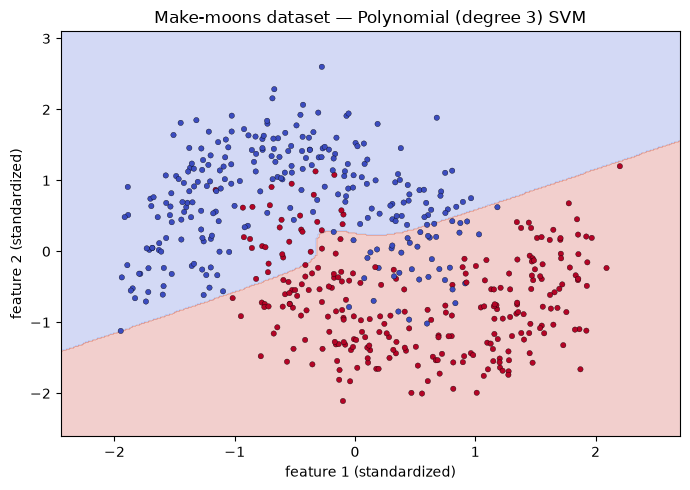

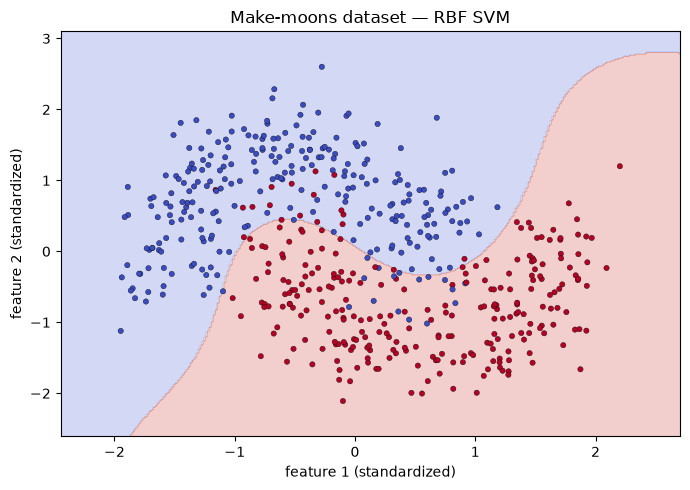

,kernel,test_accuracy
0,Linear,0.897143
1,Polynomial (degree 3),0.885714
2,RBF,0.937143


In [12]:

X_moons, y_moons = make_moons(n_samples=700, noise=0.22, random_state=RANDOM_STATE)
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.25, random_state=RANDOM_STATE, stratify=y_moons
)
moon_scaler = StandardScaler().fit(X_moons_train)
X_moons_train_s = moon_scaler.transform(X_moons_train)
X_moons_test_s = moon_scaler.transform(X_moons_test)

kernel_models = {
    "Linear": SVC(kernel="linear", C=1.0),
    "Polynomial (degree 3)": SVC(kernel="poly", degree=3, C=1.0, gamma="scale"),
    "RBF": SVC(kernel="rbf", C=1.0, gamma="scale")
}
kernel_scores = []
for name, model in kernel_models.items():
    model.fit(X_moons_train_s, y_moons_train)
    pred = model.predict(X_moons_test_s)
    kernel_scores.append({"kernel": name, "test_accuracy": accuracy_score(y_moons_test, pred)})
    xx, yy = np.meshgrid(np.linspace(X_moons_train_s[:,0].min()-0.5, X_moons_train_s[:,0].max()+0.5, 300),
                         np.linspace(X_moons_train_s[:,1].min()-0.5, X_moons_train_s[:,1].max()+0.5, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)
    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    plt.scatter(X_moons_train_s[:,0], X_moons_train_s[:,1], c=y_moons_train, s=15, edgecolors="k", linewidths=0.25, cmap="coolwarm")
    plt.title(f"Make-moons dataset — {name} SVM")
    plt.xlabel("feature 1 (standardized)"); plt.ylabel("feature 2 (standardized)")
    plt.tight_layout()
    safe_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    plt.savefig(OUTPUT_DIR / f"moons_{safe_name}.png", dpi=160)
    plt.show()

kernel_score_df = pd.DataFrame(kernel_scores)
display(kernel_score_df)
kernel_score_df.to_csv(OUTPUT_DIR / "kernel_svm_comparison.csv", index=False)


## Part D — Final Four-Feature Comparison

In [13]:

# The same stratified split is used for every model in the final comparison.
# Scaling is fitted on training data only for SVMs; decision trees use raw features.
scaler_all = StandardScaler().fit(X_train)
X_train_scaled = scaler_all.transform(X_train)
X_test_scaled = scaler_all.transform(X_test)

def metric_row(name, y_true, y_pred, train_seconds, prediction_seconds):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1_score": f1_score(y_true, y_pred, zero_division=0),
        "training_seconds": train_seconds,
        "prediction_seconds": prediction_seconds
    }

final_rows = []

manual_tree_all = ManualDecisionTree(criterion="gini", max_depth=5)
start = time.perf_counter(); manual_tree_all.fit(X_train, y_train); train_sec = time.perf_counter()-start
start = time.perf_counter(); pred = manual_tree_all.predict(X_test); pred_sec = time.perf_counter()-start
final_rows.append(metric_row("Manual Decision Tree (Gini, depth=5)", y_test, pred, train_sec, pred_sec))

sk_tree_all = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=RANDOM_STATE)
start = time.perf_counter(); sk_tree_all.fit(X_train, y_train); train_sec = time.perf_counter()-start
start = time.perf_counter(); pred = sk_tree_all.predict(X_test); pred_sec = time.perf_counter()-start
final_rows.append(metric_row("Scikit-learn Decision Tree (Gini, depth=5)", y_test, pred, train_sec, pred_sec))

manual_svm_all = ManualLinearSVM(C=1.0, learning_rate=0.01, n_iter=8000)
start = time.perf_counter(); manual_svm_all.fit(X_train_scaled, y_train); train_sec = time.perf_counter()-start
y_test_pm = np.where(y_test == np.unique(y_train)[0], -1, 1)
start = time.perf_counter(); pred_pm = manual_svm_all.predict(X_test_scaled); pred_sec = time.perf_counter()-start
pred = np.where(pred_pm == -1, np.unique(y_train)[0], np.unique(y_train)[-1])
final_rows.append(metric_row("Manual Linear SVM", y_test, pred, train_sec, pred_sec))

sk_linear_all = SVC(kernel="linear", C=1.0)
start = time.perf_counter(); sk_linear_all.fit(X_train_scaled, y_train); train_sec = time.perf_counter()-start
start = time.perf_counter(); pred = sk_linear_all.predict(X_test_scaled); pred_sec = time.perf_counter()-start
final_rows.append(metric_row("Scikit-learn Linear SVM", y_test, pred, train_sec, pred_sec))

sk_rbf_all = SVC(kernel="rbf", C=1.0, gamma="scale")
start = time.perf_counter(); sk_rbf_all.fit(X_train_scaled, y_train); train_sec = time.perf_counter()-start
start = time.perf_counter(); pred = sk_rbf_all.predict(X_test_scaled); pred_sec = time.perf_counter()-start
final_rows.append(metric_row("Scikit-learn RBF SVM", y_test, pred, train_sec, pred_sec))

final_results = pd.DataFrame(final_rows).sort_values("f1_score", ascending=False)
display(final_results)
final_results.to_csv(OUTPUT_DIR / "final_model_comparison.csv", index=False)


,model,accuracy,precision,recall,f1_score,training_seconds,prediction_seconds
4,Scikit-learn RBF SVM,1.000000,1.000000,1.000000,1.000000,0.002394,0.001089
0,"Manual Decision Tree (Gini, depth=5)",0.985423,0.974194,0.993421,0.983713,0.150325,0.000228
1,"Scikit-learn Decision Tree (Gini, depth=5)",0.985423,0.974194,0.993421,0.983713,0.001436,0.000155
3,Scikit-learn Linear SVM,0.976676,0.950000,1.000000,0.974359,0.003514,0.000388
2,Manual Linear SVM,0.892128,0.952756,0.796053,0.867384,0.601196,0.000067


## Part D — Performance Analysis

In [14]:

print("Final comparison (higher metric values are better; times are machine-dependent):")
display(final_results.round(4))

print("\nInterpretation:")
print("- Decision trees are easy to explain through feature-threshold rules, but deep trees can overfit.")
print("- SVMs depend on feature scale, so the scaler is fitted only on training data.")
print("- A linear SVM gives a straight separating boundary; an RBF SVM can model nonlinear patterns.")
print("- Manual implementations prioritize transparency and learning; optimized library implementations are generally faster.")
print("- Compare precision, recall, and F1 alongside accuracy, especially if class counts differ.")


Final comparison (higher metric values are better; times are machine-dependent):


,model,accuracy,precision,recall,f1_score,training_seconds,prediction_seconds
4,Scikit-learn RBF SVM,1.0000,1.0000,1.0000,1.0000,0.0024,0.0011
0,"Manual Decision Tree (Gini, depth=5)",0.9854,0.9742,0.9934,0.9837,0.1503,0.0002
1,"Scikit-learn Decision Tree (Gini, depth=5)",0.9854,0.9742,0.9934,0.9837,0.0014,0.0002
3,Scikit-learn Linear SVM,0.9767,0.9500,1.0000,0.9744,0.0035,0.0004
2,Manual Linear SVM,0.8921,0.9528,0.7961,0.8674,0.6012,0.0001



Interpretation:
- Decision trees are easy to explain through feature-threshold rules, but deep trees can overfit.
- SVMs depend on feature scale, so the scaler is fitted only on training data.
- A linear SVM gives a straight separating boundary; an RBF SVM can model nonlinear patterns.
- Manual implementations prioritize transparency and learning; optimized library implementations are generally faster.
- Compare precision, recall, and F1 alongside accuracy, especially if class counts differ.


## Reproducibility Check

In [15]:

required_plots = [
    "manual_tree_boundary.png", "sklearn_tree_boundary.png", "manual_tree_structure.png",
    "manual_svm_margins.png", "sklearn_svm_boundary.png",
    "moons_linear.png", "moons_polynomial_degree_3.png", "moons_rbf.png"
]
print("Expected plot files:")
for filename in required_plots:
    print(f"{filename}: {'created' if (OUTPUT_DIR / filename).exists() else 'will be created when the notebook is run'}")
print("\nSaved comparison CSVs:", sorted(p.name for p in OUTPUT_DIR.glob("*.csv")))


Expected plot files:
manual_tree_boundary.png: created
sklearn_tree_boundary.png: created
manual_tree_structure.png: created
manual_svm_margins.png: created
sklearn_svm_boundary.png: created
moons_linear.png: created
moons_polynomial_degree_3.png: created
moons_rbf.png: created

Saved comparison CSVs: ['final_model_comparison.csv', 'kernel_svm_comparison.csv', 'svm_experiments.csv']
